# Краевые поля и хроматичность высших порядков: COSY FR 0/3 против всех моделей Bell
Решётка `magnetic_2_md` (дейтроны 270 МэВ, 16 диполей BM, секступоли выключены `k2 = 0`).
Ноутбук только **читает** готовые результаты:

* `COSY/chrom_cmp.fox` → `COSY/output/cosy_mu_series.csv` (запуск `COSY/run_cosy.bat`, ~25 мин из‑за OV 7 с FR 3);
* `BELL/run.jl` → `BELL/output/bell_models.csv`, `bell_q_series.csv` (запуск `BELL/run_bell.bat`, ~2 мин).

**GAP** — полу‑апертура (половина зазора / радиус камеры), как в COSY. Для диполя полный зазор $g = 2\,\mathrm{GAP}$,
поэтому в Bell `Enge(gap = 2GAP)`. **Краевые поля секступолей нигде не учитываются** (COSY: FR 0 для MH; Bell: `sext = NoEdge`).

## 1. Что такое каждая модель
**COSY** (`FR n` перед элементом):
* **FR 0** — жёсткий край без краевых эффектов вообще: поле — ступенька, никакой фокусировки торцом (для диполя с $e_1=e_2=0$ нет даже линейной вертикальной краевой фокусировки).
* **FR 3** — «полный» мягкий край: поле вдоль оси спадает по профилю Энге $F(z)=1/(1+e^{P(z/D)})$ с масштабом $D$ = полный зазор ($2\,\mathrm{GAP}$) для диполя / диаметр апертуры для квадруполя, и карта интегрируется численно (DA + RK) до порядка OV, включая все нелинейные (по $x,y,\delta$) члены разложения поля вне оси.

Варианты COSY: (FD, FQ) = (0,0) **FR0**; (3,0) **FR3 только диполи**; (0,3) **FR3 только квадруполи**; (3,3) **FR3 диполи+квадруполи** («всё кольцо», секступоли всё равно FR 0).
В варианте с квадрупольным FR 3 их апертура тоже равна GAP (градиент от этого не меняется: в `MQ` задано поле на полюсе $B = k\cdot AP$ при радиусе $AP$).

**Bell** (`FringeModel(dipole=…, quad=…, sext=NoEdge())`):
* **NoEdge** — то же, что COSY FR 0.
* **HardEdge(order=1)** — линейный тонкий край $p_x \mathrel{+}= h\tan\varepsilon\,x,\ p_y \mathrel{-}= h\tan\psi\,y$; при $\varepsilon=0$, FINT=0 это тождество.
* **HardEdge(order=2,3)** — нелинейный жёсткий край (вертикальный член через $\tan(\psi\pm x')$ с точным $x'=p_x/p_s$; генератор до степени 3 или 4). Это предел FR 3 при GAP→0. Для квадруполя order≥2 — кубический генератор Ли (Lee‑Whiting / Forest).
* **HardEdge(2, gap, FINT)** — тот же край с FINT профиля Энге (линейная поправка за конечный зазор).
* **SoftEdge(profile, method)** — интегрирование $s$‑зависимого гамильтониана по области $[-W,W]$ вокруг эффективной границы поля, **только для диполей** (для квадруполей в Bell мягкого края нет).
  * профили: `Enge(gap=2GAP)` (коэффициенты COSY по умолчанию), `Tanh(λ)`, `LinearRamp(w)`, `Tabulated` (Энге, затабулированный в 403…409 точках). Ширины λ, w подобраны так, что **интеграл края $I=\int F(1-F)dz$ совпадает с энговским** → одинаковый FINT, одинаковый линейный вертикальный эффект; разница между профилями — только эффект высших моментов профиля.
  * методы: `Splitting(n=40, order=4)` (произведение точных карт слоёв, Йошида), `Magnus(n=40, order=4)`, `TaylorIntegrate(tol=1e-10)` (RK4 в TaylorN, эталон).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import factorial, sqrt
pd.set_option('display.width', 200); pd.set_option('display.max_rows', 200)
M = 1875.612945; T = 270.0; g = 1 + T/M; bg = sqrt(g*g - 1)
cosy = pd.read_csv('COSY/output/cosy_mu_series.csv', skipinitialspace=True)
for c in ['FD','FQ','k']: cosy[c] = cosy[c].round().astype(int)
cosy['GAP'] = cosy['GAP'].round(6)
bell = pd.read_csv('BELL/output/bell_models.csv'); bser = pd.read_csv('BELL/output/bell_q_series.csv')
bell['gap'] = bell['gap'].round(6); bser['gap'] = bser['gap'].round(6)
print('gamma =', g, ' 1+1/gamma =', 1+1/g)

gamma = 1.1439529412077074  1+1/gamma = 1.8741618330420726


## 2. Нормировка COSY и пересчёт к $\delta = \Delta p/p$
`TP MU` при `OV NO 2 1` даёт дробные бетатронные частоты как DA‑многочлен по 5‑й переменной COSY — **относительному отклонению кинетической энергии** $\delta_K=\Delta K/K$. В файл пишется `MU|(0&0&0&0&k)` = **коэффициент Тейлора** $\mu_k$: $Q(\delta_K)=\sum_k \mu_k\delta_K^k$ (не производная, без $k!$).
Точная связь: $1+\delta_K = \dfrac{\sqrt{1+(\beta\gamma)^2(1+\delta)^2}-1}{\gamma-1}$, т.е. $\delta_K=(1+1/\gamma)\delta+\dots$ (это и есть множитель `F = 1+1/G` из старых программ). Ряд $\delta_K(\delta)$ подставляется в $Q(\delta_K)$ до порядка 6. Далее
$$Q(\delta)=\sum_n q_n\delta^n,\qquad \xi_n \equiv \frac{d^nQ}{d\delta^n}\Big|_0 = n!\,q_n .$$
В Bell `xi2` = $d^2Q/d\delta^2$ = $2q_2$ (так же определено в `chromaticity_orders`). В таблицах даны и $q_n$, и $\xi_n$.

Точность COSY: при OV 7 частота как функция $\delta_K$ получается до $\delta_K^6$, но старший коэффициент (k = 6) зависит от отброшенных членов карты порядка 8 → считаем надёжными $k\le5$.

In [2]:
N = 6
# series of dK(delta) up to delta^N by Taylor of the exact relation (numerical, high-precision polyfit on tiny grid is ill-posed -> use recurrence via numpy poly composition of sqrt)
def dK_series(N):
    # f(d) = (sqrt(1+bg^2 (1+d)^2) - 1)/(g-1) - 1 ; Taylor via sqrt(a + b d + c d^2) series
    a, b, c = 1+bg**2, 2*bg**2, bg**2
    # s(d)=sqrt(a+b d+c d^2): s^2 = P  -> s_n by recurrence
    P = [a, b, c] + [0]*N; s = [sqrt(a)] + [0]*N
    for n in range(1, N+1):
        s[n] = (P[n] - sum(s[i]*s[n-i] for i in range(1, n))) / (2*s[0])
    f = np.array(s)/(g-1); f[0] -= 1/(g-1) + 1
    return f   # f[0] = 0
fK = dK_series(N); print('dK = ', ' + '.join(f'{v:.6g} d^{i}' for i, v in enumerate(fK) if i))
def to_delta(mu):
    out = np.zeros(N+1); p = np.zeros(N+1); p[0] = 1.0
    for k in range(len(mu)):
        out += mu[k]*p
        p = np.convolve(p, fK)[:N+1]
    return out
rows = []
names = {(0,0):'FR0', (3,0):'FR3 диполи', (0,3):'FR3 квадруполи', (3,3):'FR3 диполи+квадруполи'}
for (fd, fq, gap), d in cosy.groupby(['FD','FQ','GAP']):
    d = d.sort_values('k')
    for pl, col in [('x','MUx_k'), ('y','MUy_k')]:
        q = to_delta(d[col].values)
        rows.append(dict(variant=names[(fd,fq)], FD=fd, FQ=fq, GAP=gap, plane=pl, **{f'q{n}': q[n] for n in range(N+1)},
                         **{f'mu{n}': d[col].values[n] for n in range(N+1)}))
cq = pd.DataFrame(rows)
for n in range(1, N+1): cq[f'xi{n}'] = factorial(n)*cq[f'q{n}']
cq.to_csv('cosy_q_delta.csv', index=False)
cq[cq.plane=='y'][['variant','GAP','q0','xi1','xi2','xi3','xi4','xi5']]

dK =  1.87416 d^1 + 0.716079 d^2 + -0.168881 d^3 + 0.00756609 d^4 + 0.0134335 d^5 + -0.00564444 d^6


,variant,GAP,q0,xi1,xi2,xi3,xi4,xi5
1,FR0,0.00625,0.461337,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
3,FR0,0.01250,0.461337,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
5,FR0,0.02500,0.461337,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
7,FR0,0.05000,0.461337,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
9,FR3 квадруполи,0.00625,0.461273,-2.225332,80.084668,-85.925593,4.669274e+06,4.860134e+07
11,FR3 квадруполи,0.01250,0.461090,-2.224894,78.280192,-84.613102,2.267526e+06,2.311372e+07
13,FR3 квадруполи,0.02500,0.460384,-2.223202,74.722750,-81.912221,1.079589e+06,1.057778e+07
15,FR3 квадруполи,0.05000,0.457732,-2.216842,67.752345,-76.235744,5.086117e+05,4.679150e+06
17,FR3 диполи,0.00625,0.460633,-1.815876,7.362756,-33.656781,2.001696e+02,-3.638447e+03
19,FR3 диполи,0.01250,0.459929,-1.814692,7.356074,-33.616667,1.995835e+02,-3.624527e+03


**Таблица выше** — вертикальная частота $Q_y$ и хроматичности $\xi_n=d^nQ_y/d\delta^n$ ($\delta=\Delta p/p$) для всех вариантов COSY. Для FR0 строки не зависят от GAP (апертура при FR 0 не используется) — это проверка. Ниже то же для $x$.

In [3]:
cq[cq.plane=='x'][['variant','GAP','q0','xi1','xi2','xi3','xi4','xi5']]

,variant,GAP,q0,xi1,xi2,xi3,xi4,xi5
0,FR0,0.00625,0.461720,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
2,FR0,0.01250,0.461720,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
4,FR0,0.02500,0.461720,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
6,FR0,0.05000,0.461720,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
8,FR3 квадруполи,0.00625,0.461664,-1.461380,146.014067,-141.680596,1.927042e+07,2.707636e+08
10,FR3 квадруполи,0.01250,0.461505,-1.460929,142.382155,-138.177459,9.560102e+06,1.333420e+08
12,FR3 квадруполи,0.02500,0.460888,-1.459187,135.190712,-130.913895,4.727455e+06,6.514920e+07
14,FR3 квадруполи,0.05000,0.458571,-1.452627,121.001405,-115.583133,2.350376e+06,3.197284e+07
16,FR3 диполи,0.00625,0.461720,-1.461535,8.554584,-26.879752,2.614980e+02,-4.159734e+03
18,FR3 диполи,0.01250,0.461720,-1.461533,8.554551,-26.879547,2.614951e+02,-4.159683e+03


## 3. Модели Bell: $Q$, $\xi_1$, $\xi_2$
`fringe_observables`‑эквивалент: Ли‑фактор кольца → полиномиальная карта → `chromaticity_orders` (замкнутая орбита при $\delta=0,\pm10^{-4}$, частоты из якобиана). Колонка `seconds` — время одного варианта.

In [4]:
bell[['variant','gap','width_param','Qx','Qy','xi1x','xi1y','xi2x','xi2y','seconds']]

,variant,gap,width_param,Qx,Qy,xi1x,xi1y,xi2x,xi2y,seconds
0,NoEdge,NaN,NaN,0.461720,0.461337,-1.461538,-2.225488,8.554735,8.104123,2.31
1,HardEdge1,NaN,NaN,0.461720,0.461337,-1.461538,-2.225488,8.554735,8.104123,0.57
2,HardEdge2,NaN,NaN,0.461720,0.461337,-1.461538,-1.817066,8.554735,8.186520,0.14
3,HardEdge3,NaN,NaN,0.461720,0.461337,-1.461538,-1.817065,8.554735,7.369658,0.14
4,Quad_HardEdge2,NaN,NaN,0.461720,0.461337,-1.461564,-2.225509,149.678767,81.912686,0.34
5,HardEdge2+Quad_HardEdge2,NaN,NaN,0.461720,0.461337,-1.461564,-1.817083,149.678767,81.994277,0.18
6,HardEdge2_FINT,0.05000,0.369458,0.461720,0.455693,-1.461538,-1.813213,8.554735,8.165398,0.16
7,Soft_Enge_Splitting,0.05000,0.100000,0.461720,0.455729,-1.464386,-1.806663,8.561409,7.326314,1.56
8,Soft_Enge_Magnus,0.05000,0.100000,0.461723,0.455727,-1.464396,-1.806660,8.561405,7.326299,0.60
9,Soft_Enge_TaylorIntegrate,0.05000,0.100000,0.461720,0.455729,-1.464386,-1.806663,8.561409,7.326315,2.52


## 4. Сводная таблица: COSY против Bell (линейная хроматичность)
Разности $\Delta = $ Bell − COSY для соответствующих пар: NoEdge↔FR0; SoftEdge Enge/Splitting (диполи) ↔ FR3 диполи; Soft Enge + Quad HardEdge(2) ↔ FR3 диполи+квадруполи.

In [5]:
def cpick(v, gap, pl, col='xi1'):
    r = cq[(cq.variant==v)&(cq.plane==pl)&(np.isclose(cq.GAP, gap))]; return float(r[col].iloc[0])
def bpick(v, gap, col):
    r = bell[(bell.variant==v)&((np.isclose(bell.gap, gap)) if gap==gap else bell.gap.isna())]; return float(r[col].iloc[0])
GAPS = [0.05, 0.025, 0.0125, 0.00625]; S = []
for gp in GAPS:
    for bv, cv, bg_ in [('NoEdge','FR0',np.nan), ('Soft_Enge_Splitting','FR3 диполи',gp), ('Soft_Enge_Splitting+Quad_HardEdge2','FR3 диполи+квадруполи',gp)]:
        S.append(dict(GAP=gp, Bell=bv, COSY=cv,
                      Qy_B=bpick(bv,bg_,'Qy'), Qy_C=cpick(cv,gp,'y','q0'),
                      xiy_B=bpick(bv,bg_,'xi1y'), xiy_C=cpick(cv,gp,'y'), dxiy=bpick(bv,bg_,'xi1y')-cpick(cv,gp,'y'),
                      xix_B=bpick(bv,bg_,'xi1x'), xix_C=cpick(cv,gp,'x'), dxix=bpick(bv,bg_,'xi1x')-cpick(cv,gp,'x')))
summ = pd.DataFrame(S); summ.to_csv('summary_xi1.csv', index=False); summ

,GAP,Bell,COSY,Qy_B,Qy_C,xiy_B,xiy_C,dxiy,xix_B,xix_C,dxix
0,0.05000,NoEdge,FR0,0.461337,0.461337,-2.225488,-2.225485,-0.000003,-1.461538,-1.461536,-0.000002
1,0.05000,Soft_Enge_Splitting,FR3 диполи,0.455729,0.455729,-1.806663,-1.807670,0.001007,-1.464386,-1.461498,-0.002888
2,0.05000,Soft_Enge_Splitting+Quad_HardEdge2,FR3 диполи+квадруполи,0.455729,0.452122,-1.806678,-1.796928,-0.009750,-1.464412,-1.452590,-0.011823
3,0.02500,NoEdge,FR0,0.461337,0.461337,-2.225488,-2.225485,-0.000003,-1.461538,-1.461536,-0.000002
4,0.02500,Soft_Enge_Splitting,FR3 диполи,0.458525,0.458525,-1.811833,-1.812336,0.000503,-1.462980,-1.461526,-0.001454
5,0.02500,Soft_Enge_Splitting+Quad_HardEdge2,FR3 диполи+квадруполи,0.458525,0.457571,-1.811849,-1.809500,-0.002349,-1.463007,-1.459178,-0.003829
6,0.01250,NoEdge,FR0,0.461337,0.461337,-2.225488,-2.225485,-0.000003,-1.461538,-1.461536,-0.000002
7,0.01250,Soft_Enge_Splitting,FR3 диполи,0.459929,0.459929,-1.814441,-1.814692,0.000250,-1.462264,-1.461533,-0.000731
8,0.01250,Soft_Enge_Splitting+Quad_HardEdge2,FR3 диполи+квадруполи,0.459929,0.459682,-1.814458,-1.813959,-0.000499,-1.462290,-1.460927,-0.001363
9,0.00625,NoEdge,FR0,0.461337,0.461337,-2.225488,-2.225485,-0.000003,-1.461538,-1.461536,-0.000002


## 5. $\xi_y$ и $\xi_x$ в зависимости от GAP
**Рисунок 1.** Слева — вертикальная, справа — горизонтальная линейная хроматичность в зависимости от полу‑апертуры GAP. Квадраты — COSY (FR0 — серые, FR3 диполи — чёрные, FR3 квадруполи — синие, FR3 диполи+квадруполи — красные). Линии — мягкий край Bell (4 профиля × 3 метода, все с одинаковым интегралом края), пунктир — жёсткий край Bell HardEdge(2) (предел GAP→0) и HardEdge(2)+FINT. Модели, не зависящие от GAP (NoEdge, HardEdge1/2/3), показаны горизонтальными линиями. NoEdge/FR0 по $y$ ≈ −2.225 — вне масштаба, указаны в подписи.

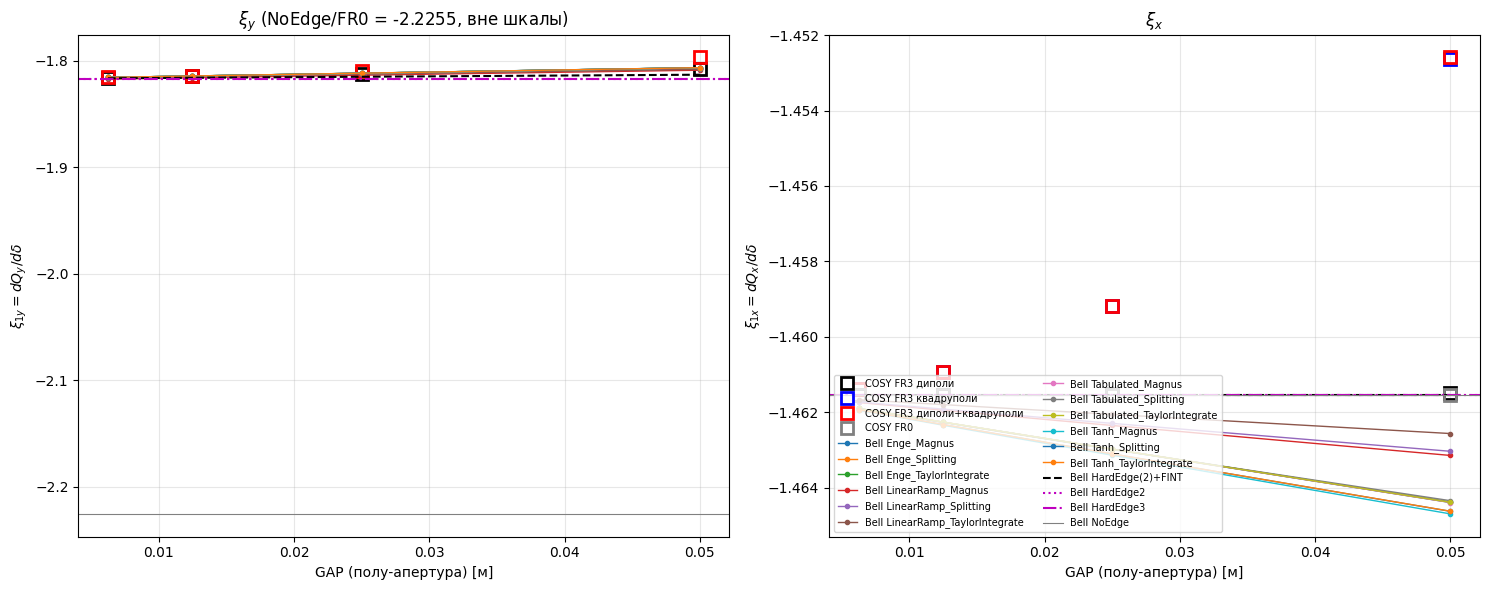

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for i, pl in enumerate(['y', 'x']):
    a = ax[i]; key = 'xi1'+pl
    for v, c in [('FR3 диполи','k'), ('FR3 квадруполи','b'), ('FR3 диполи+квадруполи','r'), ('FR0','gray')]:
        d = cq[(cq.variant==v)&(cq.plane==pl)].sort_values('GAP')
        if pl=='y' and v in ('FR0','FR3 квадруполи'): continue
        a.plot(d.GAP, d.xi1, 's', color=c, ms=9, mfc='none', mew=2, label='COSY '+v)
    soft = bell[bell.variant.str.startswith('Soft_') & ~bell.variant.str.contains('Quad')]
    for v, d in soft.groupby('variant'):
        d = d.sort_values('gap'); a.plot(d.gap, d[key], '-', marker='.', lw=1, label='Bell '+v[5:])
    d = bell[bell.variant=='HardEdge2_FINT'].sort_values('gap'); a.plot(d.gap, d[key], 'k--', label='Bell HardEdge(2)+FINT')
    for v, ls in [('HardEdge2', ':'), ('HardEdge3', '-.')]:
        a.axhline(bpick(v, np.nan, key), ls=ls, color='m', label='Bell '+v)
    a.axhline(bpick('NoEdge', np.nan, key), color='gray', lw=0.8, label='Bell NoEdge' if pl=='x' else None)
    a.set_xlabel('GAP (полу-апертура) [м]'); a.set_ylabel(r'$\xi_{1%s}=dQ_%s/d\delta$' % (pl, pl)); a.grid(alpha=.3)
ax[0].set_title(r'$\xi_y$ (NoEdge/FR0 = %.4f, вне шкалы)' % bpick('NoEdge', np.nan, 'xi1y')); ax[1].set_title(r'$\xi_x$')
ax[1].legend(fontsize=7, ncol=2, loc='lower left'); plt.tight_layout(); plt.savefig('xi_vs_gap.png', dpi=110); plt.show()

**Рисунок 2.** Разность Bell − COSY FR3 (только диполи) для $\xi_y$ (слева) и $\xi_x$ (справа) для всех мягких моделей Bell, в логарифмическом масштабе по GAP. Линейный рост с GAP означает, что расхождение — эффект конечной длины края (порядок $g/\rho$, $g^2$…), а не ошибка жёсткого предела: при GAP→0 обе программы сходятся к HardEdge(2).

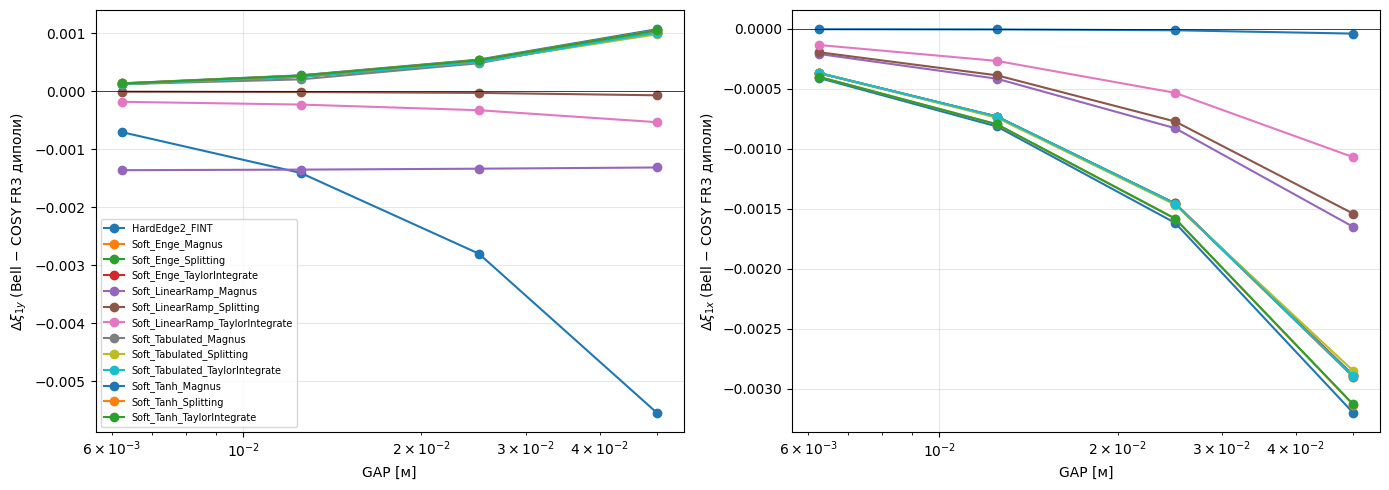

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, pl in enumerate(['y','x']):
    ref = cq[(cq.variant=='FR3 диполи')&(cq.plane==pl)].set_index('GAP')['xi1']
    for v, d in bell[bell.variant.str.startswith('Soft_') & ~bell.variant.str.contains('Quad') | (bell.variant=='HardEdge2_FINT')].groupby('variant'):
        d = d.sort_values('gap'); ax[i].plot(d.gap, d['xi1'+pl].values - ref.loc[d.gap.values].values, marker='o', label=v)
    ax[i].set_xscale('log'); ax[i].axhline(0, color='k', lw=.5); ax[i].grid(alpha=.3)
    ax[i].set_xlabel('GAP [м]'); ax[i].set_ylabel(r'$\Delta\xi_{1%s}$ (Bell − COSY FR3 диполи)' % pl)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('dxi_vs_gap.png', dpi=110); plt.show()

## 6. Вклад краевых полей квадруполей в COSY
**Рисунок 3.** Разность «FR3 только квадруполи − FR0» в COSY (сплошные) и «Bell Quad HardEdge(2) − NoEdge» (пунктир, не зависит от GAP) для $Q_x,Q_y$ (слева) и $\xi_{1x},\xi_{1y}$ (справа). Также показан вклад квадруполей поверх диполей: (FR3 диполи+квадр.) − (FR3 диполи).

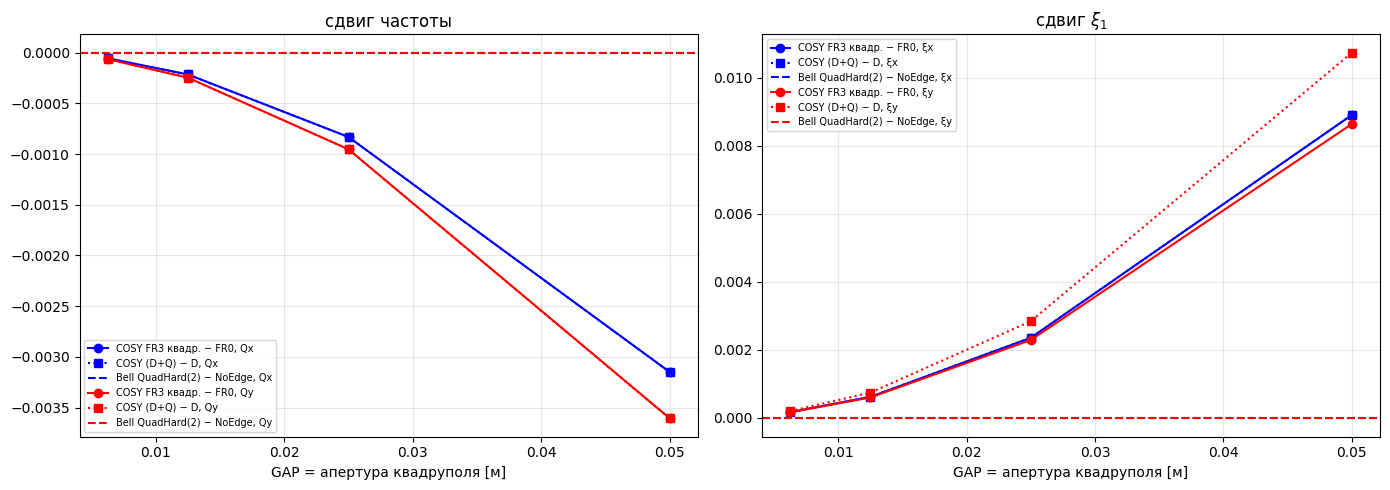

,GAP,dQx,dQy,dxi1x,dxi1y,dxi2x,dxi2y
0,0.00625,-0.000056,-0.000064,0.000156,0.000153,137.459471,71.980877
1,0.01250,-0.000216,-0.000247,0.000606,0.000591,133.827560,70.176401
2,0.02500,-0.000832,-0.000954,0.002348,0.002282,126.636117,66.618958
3,0.05000,-0.003149,-0.003605,0.008909,0.008643,112.446809,59.648554


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
def cv(v, pl, col): return cq[(cq.variant==v)&(cq.plane==pl)].sort_values('GAP')[col].values
G = np.array(sorted(GAPS))
for pl, c in [('x','b'), ('y','r')]:
    ax[0].plot(G, cv('FR3 квадруполи',pl,'q0') - cv('FR0',pl,'q0'), c+'-o', label=f'COSY FR3 квадр. − FR0, Q{pl}')
    ax[0].plot(G, cv('FR3 диполи+квадруполи',pl,'q0') - cv('FR3 диполи',pl,'q0'), c+':s', label=f'COSY (D+Q) − D, Q{pl}')
    ax[0].axhline(bpick('Quad_HardEdge2',np.nan,'Q'+pl) - bpick('NoEdge',np.nan,'Q'+pl), color=c, ls='--', label=f'Bell QuadHard(2) − NoEdge, Q{pl}')
    ax[1].plot(G, cv('FR3 квадруполи',pl,'xi1') - cv('FR0',pl,'xi1'), c+'-o', label=f'COSY FR3 квадр. − FR0, ξ{pl}')
    ax[1].plot(G, cv('FR3 диполи+квадруполи',pl,'xi1') - cv('FR3 диполи',pl,'xi1'), c+':s', label=f'COSY (D+Q) − D, ξ{pl}')
    ax[1].axhline(bpick('Quad_HardEdge2',np.nan,'xi1'+pl) - bpick('NoEdge',np.nan,'xi1'+pl), color=c, ls='--', label=f'Bell QuadHard(2) − NoEdge, ξ{pl}')
for a, t in zip(ax, ['сдвиг частоты', r'сдвиг $\xi_1$']):
    a.set_title(t); a.set_xlabel('GAP = апертура квадруполя [м]'); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig('quad_contribution.png', dpi=110); plt.show()
qc = pd.DataFrame({'GAP': G,
   'dQx': cv('FR3 квадруполи','x','q0')-cv('FR0','x','q0'), 'dQy': cv('FR3 квадруполи','y','q0')-cv('FR0','y','q0'),
   'dxi1x': cv('FR3 квадруполи','x','xi1')-cv('FR0','x','xi1'), 'dxi1y': cv('FR3 квадруполи','y','xi1')-cv('FR0','y','xi1'),
   'dxi2x': cv('FR3 квадруполи','x','xi2')-cv('FR0','x','xi2'), 'dxi2y': cv('FR3 квадруполи','y','xi2')-cv('FR0','y','xi2')}); qc

**Таблица** — вклад квадрупольных краёв в COSY (FR3 квадр. − FR0). Сдвиги частот и $\xi_1$ растут как $\mathrm{GAP}^2$ (каждое удвоение апертуры ×4): при 5 см $\Delta Q_x=-3.1\cdot10^{-3}$, $\Delta Q_y=-3.6\cdot10^{-3}$, $\Delta\xi_{1x}\approx\Delta\xi_{1y}\approx+8.8\cdot10^{-3}$; при 6.25 мм — $\sim10^{-4}$. Это эффект конечной длины мягкого края квадруполя ($\propto k\,a^2$). Жёсткий кубический край Bell даёт в пределе ноль для $Q$ и $\sim3\cdot10^{-5}$ для $\xi_1$ — согласуется с пределом COSY GAP→0.
Зато во **второй хроматичности** квадрупольный край — главный эффект: $\xi_{2x}$ 8.55 → 121…146, $\xi_{2y}$ 8.10 → 68…80 (COSY), а Bell Quad HardEdge(2) даёт 149.7 / 81.9 — это и есть предел COSY при GAP→0 (члены $\propto x^3p_x,\ xy^2p_x$ на дисперсионной орбите дают $\delta^2$ в частоте).

## 7. Хроматичность высших порядков
Bell: карта кольца точна до **3‑го порядка** по $(x,p_x,y,p_y,l,\delta)$ (`JET_ORDER = 4`, `MAP_ORDER = 3` — константы в `lie_algebra.jl`). Якобиан на замкнутой орбите точен до $\delta^2$ ⇒ надёжны только $Q_0,\xi_1,\xi_2$. В `bell_q_series.csv` записан полиномиальный фит $Q(\delta)$ по 17 точкам $|\delta|\le4\cdot10^{-3}$ до $\delta^4$; коэффициенты $q_3,q_4$ помечены `reliable = 0` — это артефакты обрезки карты.
COSY: OV 7, надёжны $\xi_1\dots\xi_5$.

**Таблица** — $\xi_n = n!\,q_n$ (по $\delta=\Delta p/p$): COSY FR0 vs Bell NoEdge, COSY FR3 диполи vs Bell Soft Enge Splitting при GAP = 0.05 и 0.00625 м.

In [9]:
def bq(v, gap):
    d = bser[(bser.variant==v)&((np.isclose(bser.gap,gap)) if gap==gap else bser.gap.isna())].sort_values('k'); return d
H = []
for gp, cvn, bv, bgp in [(0.05,'FR0','NoEdge',np.nan), (0.05,'FR3 диполи','Soft_Enge_Splitting',0.05), (0.00625,'FR3 диполи','Soft_Enge_Splitting',0.00625),
                          (0.05,'FR3 диполи+квадруполи','Soft_Enge_Splitting+Quad_HardEdge2',0.05)]:
    for pl in ['x','y']:
        r = cq[(cq.variant==cvn)&(cq.plane==pl)&np.isclose(cq.GAP,gp)].iloc[0]; b = bq(bv,bgp)
        H.append(dict(GAP=gp, model=f'COSY {cvn}', plane=pl, **{f'xi{n}': r[f'xi{n}'] for n in range(1,6)}))
        bb = {f'xi{n}': factorial(n)*b[f'q{pl}_k'].values[n] for n in range(1,5)}
        bb['xi1'] = bpick(bv,bgp,'xi1'+pl); bb['xi2'] = bpick(bv,bgp,'xi2'+pl)
        H.append(dict(GAP=gp, model=f'Bell {bv}', plane=pl, **bb, xi5=np.nan))
hi = pd.DataFrame(H); hi.to_csv('higher_order_table.csv', index=False); hi

,GAP,model,plane,xi1,xi2,xi3,xi4,xi5
0,0.05000,COSY FR0,x,-1.461536,8.554596,-26.879819,2.614990e+02,-4.159751e+03
1,0.05000,Bell NoEdge,x,-1.461538,8.554735,-1116.441094,1.746635e+05,NaN
2,0.05000,COSY FR0,y,-2.225485,8.103791,-41.385104,2.634764e+02,-4.722141e+03
3,0.05000,Bell NoEdge,y,-2.225488,8.104123,-1929.902539,4.342999e+05,NaN
4,0.05000,COSY FR3 диполи,x,-1.461498,8.553898,-26.875475,2.614394e+02,-4.158673e+03
5,0.05000,Bell Soft_Enge_Splitting,x,-1.464386,8.561409,-1120.018748,1.755370e+05,NaN
6,0.05000,COSY FR3 диполи,y,-1.807670,7.316550,-33.382915,1.962324e+02,-3.545161e+03
7,0.05000,Bell Soft_Enge_Splitting,y,-1.806663,7.326314,-1143.424995,1.839344e+05,NaN
8,0.00625,COSY FR3 диполи,x,-1.461535,8.554584,-26.879752,2.614980e+02,-4.159734e+03
9,0.00625,Bell Soft_Enge_Splitting,x,-1.461902,8.555646,-1116.904032,1.747759e+05,NaN


**Рисунок 4.** Модули $|\xi_n|$ ($n=1..5$, лог. шкала) для $x$ (слева) и $y$ (справа). Сплошные — COSY (FR0, FR3 диполи, FR3 квадруполи, FR3 D+Q при GAP = 5 см), маркеры‑звёзды — Bell NoEdge и Soft Enge (GAP 5 см): закрашенные — надёжные ($n\le2$), пустые — артефакты карты 3‑го порядка ($n=3,4$). Видно: (а) для $n\le2$ Bell совпадает с COSY FR0/FR3‑диполи; (б) квадрупольный FR 3 в COSY резко увеличивает $\xi_2$ и особенно $\xi_4$ — это вклад членов поля $\propto k'' (x^2+y^2)$ вне оси, растущий при уменьшении апертуры (см. рис. 5).

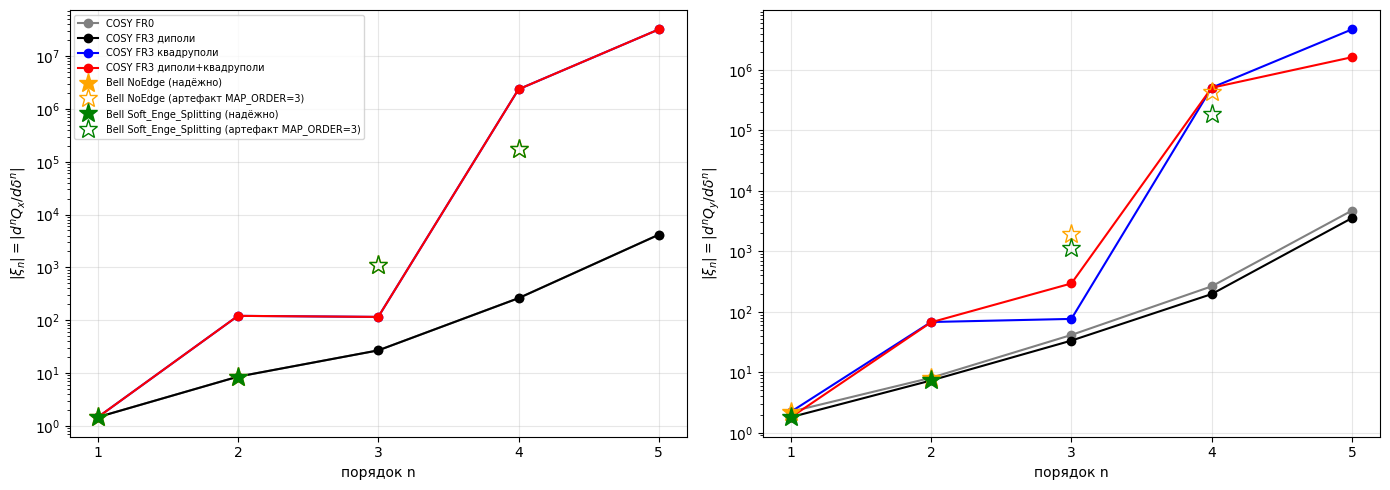

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5)); n = np.arange(1, 6)
for i, pl in enumerate(['x','y']):
    for v, c in [('FR0','gray'), ('FR3 диполи','k'), ('FR3 квадруполи','b'), ('FR3 диполи+квадруполи','r')]:
        r = cq[(cq.variant==v)&(cq.plane==pl)&np.isclose(cq.GAP,0.05)].iloc[0]
        ax[i].semilogy(n, [abs(r[f'xi{k}']) for k in n], '-o', color=c, label='COSY '+v)
    for bv, bgp, c in [('NoEdge', np.nan, 'orange'), ('Soft_Enge_Splitting', 0.05, 'green')]:
        b = bq(bv, bgp); xs = [abs(bpick(bv,bgp,'xi1'+pl)), abs(bpick(bv,bgp,'xi2'+pl))] + [abs(factorial(k)*b[f'q{pl}_k'].values[k]) for k in (3,4)]
        ax[i].semilogy([1,2], xs[:2], '*', ms=14, color=c, label='Bell '+bv+' (надёжно)')
        ax[i].semilogy([3,4], xs[2:], '*', ms=14, mfc='none', color=c, label='Bell '+bv+' (артефакт MAP_ORDER=3)')
    ax[i].set_xlabel('порядок n'); ax[i].set_ylabel(r'$|\xi_n| = |d^nQ_%s/d\delta^n|$' % pl); ax[i].grid(alpha=.3); ax[i].set_xticks(n)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('higher_order.png', dpi=110); plt.show()

**Рисунок 5.** $\xi_2$ и $\xi_3$ в зависимости от GAP для всех вариантов COSY (лево: $x$, право: $y$) и $\xi_2$ Bell (звёзды — Soft Enge Splitting, линии — NoEdge/HardEdge2). Квадрупольный FR 3 даёт большую $\xi_2$, которая при GAP→0 стремится к жёсткому пределу Bell Quad HardEdge(2) (голубая/красная штриховая). Для диполей: HardEdge(2) даёт $\xi_{2y}=8.19$, а HardEdge(3) — 7.37, что и есть предел COSY FR3 (7.363 при 6.25 мм): для $\xi_2$ нужен край 3‑го порядка.

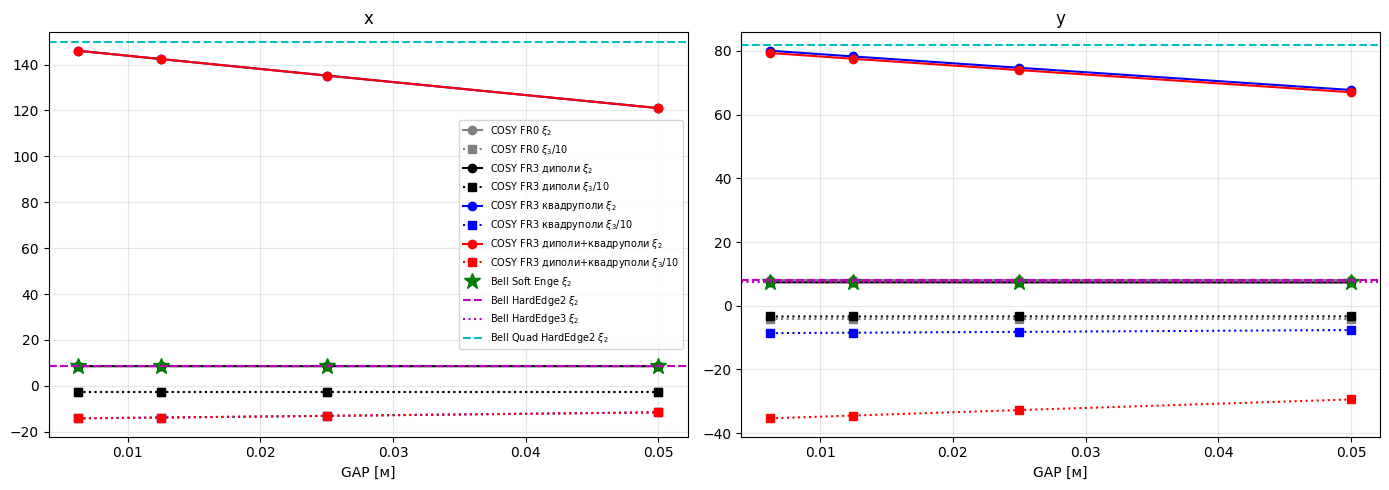

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, pl in enumerate(['x','y']):
    for v, c in [('FR0','gray'), ('FR3 диполи','k'), ('FR3 квадруполи','b'), ('FR3 диполи+квадруполи','r')]:
        d = cq[(cq.variant==v)&(cq.plane==pl)].sort_values('GAP')
        ax[i].plot(d.GAP, d.xi2, '-o', color=c, label='COSY '+v+r' $\xi_2$'); ax[i].plot(d.GAP, d.xi3/10, ':s', color=c, label='COSY '+v+r' $\xi_3/10$')
    d = bell[bell.variant=='Soft_Enge_Splitting'].sort_values('gap'); ax[i].plot(d.gap, d['xi2'+pl], 'g*', ms=12, label=r'Bell Soft Enge $\xi_2$')
    ax[i].axhline(bpick('HardEdge2',np.nan,'xi2'+pl), color='m', ls='--', label=r'Bell HardEdge2 $\xi_2$')
    ax[i].axhline(bpick('HardEdge3',np.nan,'xi2'+pl), color='m', ls=':', label=r'Bell HardEdge3 $\xi_2$')
    ax[i].axhline(bpick('Quad_HardEdge2',np.nan,'xi2'+pl), color='c', ls='--', label=r'Bell Quad HardEdge2 $\xi_2$')
    ax[i].set_xlabel('GAP [м]'); ax[i].set_title(pl); ax[i].grid(alpha=.3)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig('xi2_vs_gap.png', dpi=110); plt.show()

**Рисунок 6.** Сами кривые $Q(\delta)-Q_0$ на $|\delta|\le 5\cdot10^{-3}$: ряд COSY FR3 диполи (до $\delta^5$), обрезанный до $\delta^2$, и ряд Bell Soft Enge до $\delta^2$ (GAP 5 см). Нижние панели — разности; видно, какой вклад в $Q(\delta)$ дают члены $\delta^{\ge3}$ (их Bell пока не даёт).

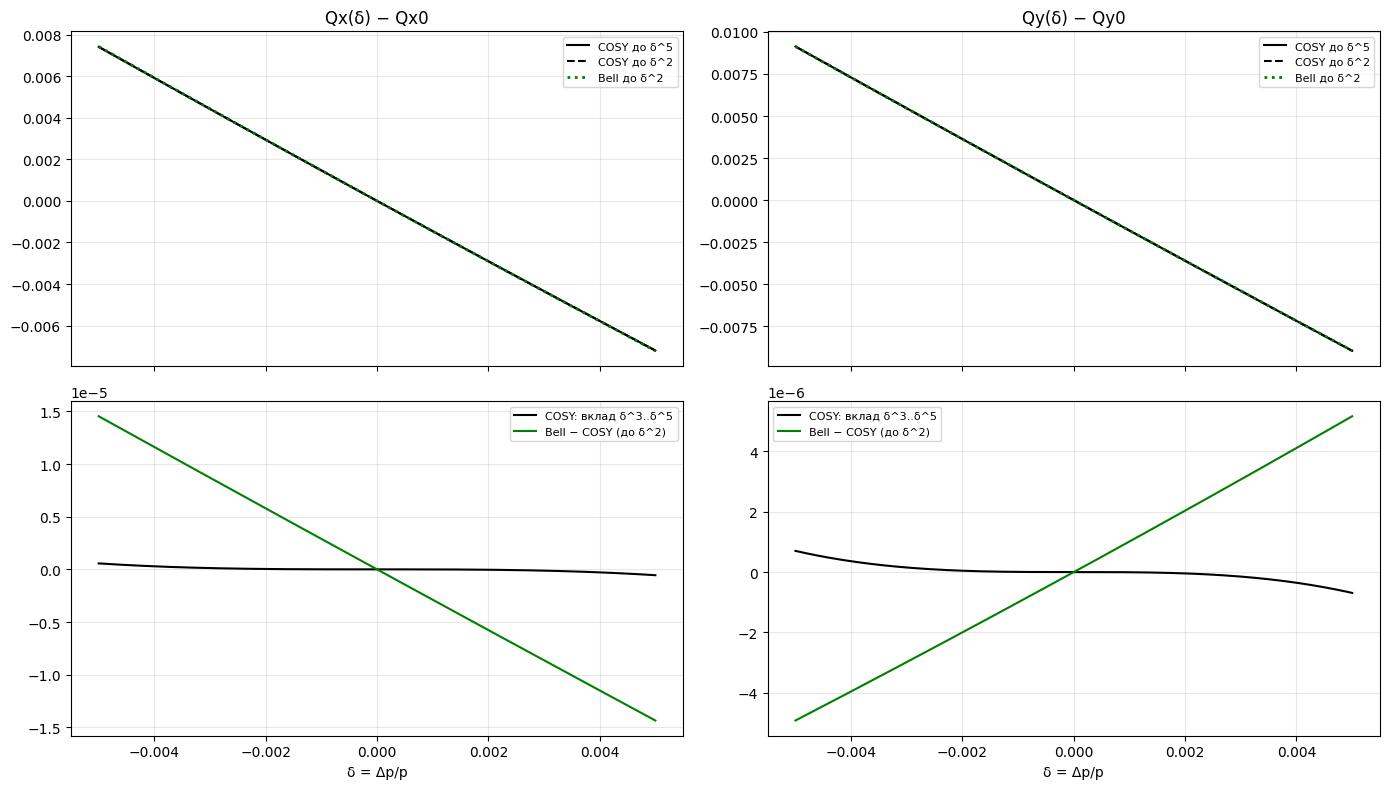

In [12]:
dd = np.linspace(-5e-3, 5e-3, 201); fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for i, pl in enumerate(['x','y']):
    r = cq[(cq.variant=='FR3 диполи')&(cq.plane==pl)&np.isclose(cq.GAP,0.05)].iloc[0]
    Qc5 = sum(r[f'q{k}']*dd**k for k in range(1,6)); Qc2 = sum(r[f'q{k}']*dd**k for k in range(1,3))
    Qb = bpick('Soft_Enge_Splitting',0.05,'xi1'+pl)*dd + bpick('Soft_Enge_Splitting',0.05,'xi2'+pl)/2*dd**2
    ax[0,i].plot(dd, Qc5, 'k', label='COSY до δ^5'); ax[0,i].plot(dd, Qc2, 'k--', label='COSY до δ^2'); ax[0,i].plot(dd, Qb, 'g:', lw=2, label='Bell до δ^2')
    ax[1,i].plot(dd, Qc5-Qc2, 'k', label='COSY: вклад δ^3..δ^5'); ax[1,i].plot(dd, Qb-Qc2, 'g', label='Bell − COSY (до δ^2)')
    ax[0,i].set_title(f'Q{pl}(δ) − Q{pl}0'); ax[1,i].set_xlabel('δ = Δp/p'); [a.grid(alpha=.3) or a.legend(fontsize=8) for a in ax[:,i]]
plt.tight_layout(); plt.savefig('q_of_delta.png', dpi=110); plt.show()

## 8. Откуда расхождение: диполи или квадруполи
Выводы ниже вычисляются по данным (ячейка печатает числа), текст — интерпретация.

In [13]:
s = summ
print('xi1 Bell NoEdge - COSY FR0:          dx = %.1e  dy = %.1e' % tuple(s[s.COSY=='FR0'][['dxix','dxiy']].iloc[0]))
for gp in GAPS:
    r = s[(s.COSY=='FR3 диполи')&np.isclose(s.GAP,gp)].iloc[0]
    print(f'GAP {gp:<8} Bell SoftEnge - COSY FR3 dip:  dxi_x = {r.dxix:+.2e}  dxi_y = {r.dxiy:+.2e}')
print(); print(qc.to_string(index=False))

xi1 Bell NoEdge - COSY FR0:          dx = -1.8e-06  dy = -3.0e-06
GAP 0.05     Bell SoftEnge - COSY FR3 dip:  dxi_x = -2.89e-03  dxi_y = +1.01e-03
GAP 0.025    Bell SoftEnge - COSY FR3 dip:  dxi_x = -1.45e-03  dxi_y = +5.03e-04
GAP 0.0125   Bell SoftEnge - COSY FR3 dip:  dxi_x = -7.31e-04  dxi_y = +2.50e-04
GAP 0.00625  Bell SoftEnge - COSY FR3 dip:  dxi_x = -3.67e-04  dxi_y = +1.24e-04

    GAP       dQx       dQy    dxi1x    dxi1y      dxi2x     dxi2y
0.00625 -0.000056 -0.000064 0.000156 0.000153 137.459471 71.980877
0.01250 -0.000216 -0.000247 0.000606 0.000591 133.827560 70.176401
0.02500 -0.000832 -0.000954 0.002348 0.002282 126.636117 66.618958
0.05000 -0.003149 -0.003605 0.008909 0.008643 112.446809 59.648554


**Анализ.**
1. **Жёсткий предел совпадает.** Bell NoEdge = COSY FR0 ($|\Delta\xi_1|\le3\cdot10^{-6}$, $\xi_2$ до $4\cdot10^{-4}$). Bell HardEdge(2/3) по $\xi_{1y}$ = −1.81707 = экстраполяция COSY FR3 (диполи) к GAP→0. HardEdge(1) при $\varepsilon=0$, FINT=0 — тождество (= NoEdge).
2. **Расхождение по $\xi_1$ — диполи.** В варианте «FR3 только диполи» Bell Soft Enge − COSY: $\Delta\xi_{1y}=+1.0\cdot10^{-3}$, $\Delta\xi_{1x}=-2.9\cdot10^{-3}$ при 5 см, строго $\propto$GAP (половина на каждом шаге). Все 3 метода Bell для гладких профилей (Enge, Tanh, Tabulated) согласуются между собой до $\sim10^{-5}$–$10^{-4}$ — это не ошибка интегратора, а разная постановка мягкого края диполя (как распределены кривизна опорной орбиты/длина пути в краю относительно EFB; в $x$ это член $\propto h\,g$). $Q_y$ при этом совпадает до $10^{-6}$ — линейная вертикальная фокусировка края (FINT) у обеих программ одинакова. LinearRamp+Magnus(40) заметно хуже (разрыв $F'$ трапеции).
3. **Квадруполи в COSY вносят материальный вклад:** $\Delta Q\approx-3\cdot10^{-3}$ и $\Delta\xi_1\approx+9\cdot10^{-3}$ при 5 см ($\propto\mathrm{GAP}^2$) — **больше**, чем дипольное расхождение; в Bell мягкого края квадруполя нет, поэтому для «всего кольца» разность Bell−COSY по $\xi_{1x}$ = −1.2·10⁻² при 5 см. При GAP ≤ 1 см эффект ≤ 6·10⁻⁴.
4. **$\xi_2$:** доминирует жёсткий кубический край квадруполей (×15 по $x$, ×10 по $y$), и Bell (Quad HardEdge(2)) воспроизводит предел COSY. Для диполей Bell Soft Enge vs COSY: $\Delta\xi_{2y}=+1\cdot10^{-2}$ (5 см) → $+1.4\cdot10^{-3}$ (6.25 мм); дипольный HardEdge(2) даёт неверную $\xi_{2y}$ (8.19 вместо 7.37), нужен HardEdge(3).
5. **$\xi_{\ge3}$:** Bell в текущем публичном API не даёт (карта 3‑го порядка: фит даёт $\xi_3\sim-1100$ вместо −27 у COSY — артефакт). У COSY с квадрупольным FR 3 $\xi_4,\xi_5\sim10^6$–$10^8$ и растут как 1/GAP (плюс предупреждения RK «minimum stepsize»): высшие порядки там определяются производными профиля Энге и сильно модельно‑зависимы; без квадрупольного края ряд COSY регулярен ($\xi_3\approx-27/-33$, $\xi_4\approx260/200$, $\xi_5\approx-4\cdot10^3$).